# Figures cho journal — Visuelle 2.0

Notebook tạo 7 figure đa sắc từ dữ liệu Visuelle 2.0.

- Chỉ xuất ảnh **PNG 600 dpi** vào thư mục `figures`.
- Không có tiêu đề lớn hoặc số thứ tự 01/02 trong ảnh; nhãn panel dùng (a), (b), (c)...
- Khung thiết kế rộng 183 mm; font DejaVu Sans và nhãn trục tiếng Anh.
- Màu mùa nhất quán; heatmap dùng thang tuần tự nhiều sắc.
- Khoảng tin cậy và cách gộp nhóm được thể hiện ở các panel liên quan.
- Cách vẽ và bảng màu dùng chung trong `figure_style.py`.


In [1]:
import gc, warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.transforms import ScaledTranslation
from PIL import Image
import torch

DATA = Path('Data/extracted/visuelle2')
OUT = Path('figures'); OUT.mkdir(exist_ok=True)
WEEKS = [str(i) for i in range(12)]
SEASONS = ['SS17', 'AW17', 'SS18', 'AW18', 'SS19', 'AW19']

MM = 1 / 25.4                       # mm → inch
SINGLE, DOUBLE = 89 * MM, 183 * MM  # độ rộng 1 cột / 2 cột

# Bảng màu phân loại (thứ tự cố định) + thang tuần tự xanh
PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
BLUE, ORANGE, GREY = PAL[0], PAL[1], '#8a8984'
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#eef5fd', '#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5',
                                                     '#256abf', '#184f95', '#0d366b'])
INK, INK2 = '#0b0b0b', '#52514e'

mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 7, 'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5,
    'legend.fontsize': 6.5, 'legend.frameon': False, 'legend.handlelength': 1.6,
    'axes.linewidth': 0.6, 'axes.edgecolor': INK2, 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2, 'xtick.labelcolor': INK, 'ytick.labelcolor': INK,
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'lines.linewidth': 1.2, 'lines.markersize': 3.5,
    'axes.prop_cycle': mpl.cycler(color=PAL),
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
    'savefig.dpi': 600, 'figure.dpi': 150, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02,
})

def panel(ax, letter, dx=-24, dy=4):
    """Nhãn panel kiểu Nature: chữ thường in đậm ở góc trên-trái."""
    off = ScaledTranslation(dx / 72, dy / 72, ax.figure.dpi_scale_trans)
    ax.text(0, 1, letter, transform=ax.transAxes + off, fontsize=9, fontweight='bold', va='bottom', ha='left')

def hgrid(ax, axis='y'):
    ax.grid(axis=axis, color='#e6e5e0', linewidth=0.4); ax.set_axisbelow(True)

def save(fig, name):
    fig.savefig(OUT / f'{name}.png', dpi=600)
    print('Saved:', name, '(PNG)')

def ci95(x):
    x = np.asarray(x, float); return 1.96 * x.std(ddof=1) / np.sqrt(len(x))
# Shared ocean / coral art direction. Data and statistical definitions are unchanged.
from figure_style import (apply_theme, PAL, SEASON_COLORS, COLOR_MAP, SEQ,
                          INK, MUTED, TEAL, CORAL, NAVY, GOLD, ramp, hgrid, panel_title)
apply_theme(journal=True)
BLUE, ORANGE, GREY, INK2 = TEAL, CORAL, MUTED, MUTED

FIGURE_LABELS = {
    'Fig1_dataset_overview': ('01', 'Dataset overview', ['Seasonal assortment', 'Store coverage', 'Sales volume', 'Product categories', 'Product colours']),
    'Fig2_sales_dynamics': ('02', 'Sales dynamics', ['Launch lifecycle', 'Seasonal trajectories', 'Product sales distribution', 'Sales concentration']),
    'Fig3_category_performance': ('03', 'Category performance', ['Category × season', 'Category ranking']),
    'Fig4_price_discount': ('04', 'Price & discount patterns', ['Discount progression', 'Discount adoption', 'Sales by discount band']),
    'Fig5_customer_behaviour': ('05', 'Customer behaviour', ['Monthly order activity', 'Shopping rhythm', 'Basket size', 'Purchase frequency', 'Day-of-week activity']),
    'Fig6_exogenous_signals': ('06', 'Exogenous signals', ['Search seasonality', 'Temperature & sales']),
    'FigS1_product_images': ('S1', 'Product gallery', ['Best sellers', 'Lowest-selling products']),
}

def panel(ax, letter, dx=None, dy=None):
    # Titles are assigned consistently at export; no outside labels to collide with ticks.
    pass

def save(fig, name):
    number, title, titles = FIGURE_LABELS[name]
    if name != 'FigS1_product_images':
        axes = [a for a in fig.axes if a.get_label() != '<colorbar>']
        for ax, letter, title in zip(axes, 'abcde', titles):
            panel_title(ax, letter, title)
    fig.savefig(OUT / f'{name}.png', dpi=600)
    print('Saved:', name, '(PNG)')

from figure_style import categorical_colors
FIGURE_LABELS['Fig1_dataset_overview'] = ('01', 'Dataset overview',
    ['New products by season', 'Retail footprint & sales', 'Category composition', 'Product colour mix'])
FIGURE_LABELS['Fig2_sales_dynamics'] = ('02', 'Sales dynamics',
    ['Launch lifecycle', 'Season × launch week', 'Sales spread by season', 'Sales concentration'])
FIGURE_LABELS['Fig4_price_discount'] = ('04', 'Price & discount patterns',
    ['Discount progression', 'Discount adoption', 'Sales by discount band'])
FIGURE_LABELS['Fig5_customer_behaviour'] = ('05', 'Customer behaviour',
    ['Monthly order activity', 'When customers shop', 'Basket composition', 'Customer purchase frequency'])


In [2]:
sales = pd.read_csv(DATA / 'sales.csv', index_col=0, parse_dates=['release_date'])
sales['total'] = sales[WEEKS].sum(axis=1)
products = sales.drop_duplicates('external_code').set_index('external_code')
prod_sales = sales.groupby('external_code').total.sum()
price = pd.read_csv(DATA / 'price_discount_series.csv')
gtrends = pd.read_csv(DATA / 'vis2_gtrends_data.csv', parse_dates=['date'])
print(sales.shape, price.shape, gtrends.shape)
CAT_COLORS = dict(zip(sorted(products.category.unique()), list(mpl.colormaps['tab20'].colors) + list(mpl.colormaps['Set2'].colors)))


(106850, 22) (106850, 15) (220, 97)


## Figure 1 — Tổng quan dataset

Saved: Fig1_dataset_overview (PNG)


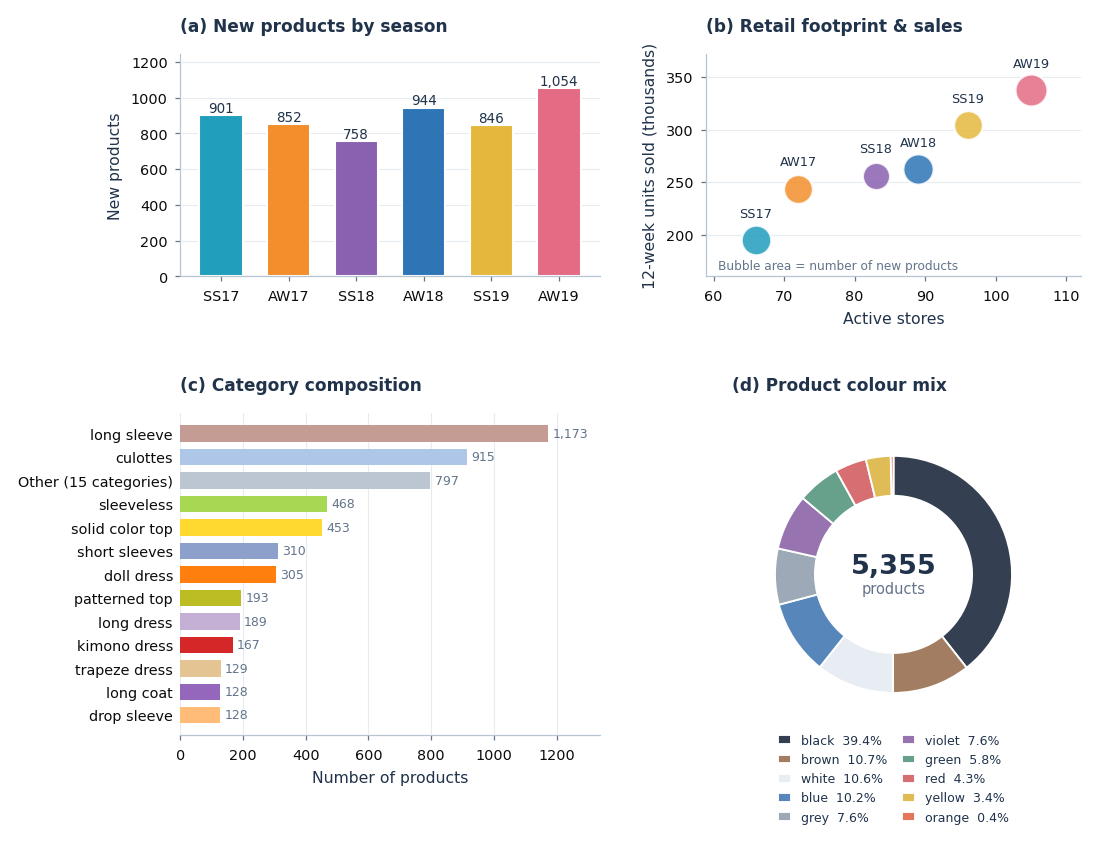

In [3]:
season = sales.groupby('season').agg(products=('external_code', 'nunique'), stores=('retail', 'nunique'),
                                     units=('total', 'sum')).reindex(SEASONS)
fig = plt.figure(figsize=(DOUBLE, 142 * MM), layout='constrained')
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.45], width_ratios=[1.12, 1])
ax = [fig.add_subplot(gs[r, c]) for r in range(2) for c in range(2)]
a = ax[0]
a.bar(SEASONS, season.products, color=SEASON_COLORS, width=.64, edgecolor='white')
for i, v in enumerate(season.products):
    a.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=6.5, color=INK)
a.set_ylabel('New products'); a.margins(y=.18); hgrid(a)
a = ax[1]
for i, (s, row) in enumerate(season.iterrows()):
    a.scatter(row.stores, row.units / 1000, s=row.products / 4.5,
              color=SEASON_COLORS[i], alpha=.85, edgecolor='white', linewidth=1, zorder=3)
    a.annotate(s, (row.stores, row.units / 1000), xytext=(0, 11), textcoords='offset points',
               ha='center', fontsize=6.2, color=INK)
a.set_xlabel('Active stores'); a.set_ylabel('12-week units sold (thousands)')
a.margins(x=.18, y=.24); hgrid(a)
a.text(.03, .03, 'Bubble area = number of new products', transform=a.transAxes, fontsize=5.8, color=INK2)
# Keep the dominant categories individually; explicitly combine the remaining 15.
counts = products.category.value_counts()
cat = pd.concat([counts.head(12), pd.Series({'Other (15 categories)': counts.iloc[12:].sum()})]).sort_values()
a = ax[2]
a.barh(cat.index, cat.values, color=[CAT_COLORS.get(c, '#BCC6D3') for c in cat.index], height=.7)
for i, v in enumerate(cat):
    a.text(v + 14, i, f'{v:,}', va='center', fontsize=6, color=INK2)
a.set_xlabel('Number of products'); a.margins(x=.14, y=.04); hgrid(a, 'x')
a.spines['left'].set_visible(False); a.tick_params(axis='y', length=0)
col = products.color.value_counts()
a = ax[3]
wedges, _ = a.pie(col.values, colors=[COLOR_MAP[c] for c in col.index], startangle=90,
    counterclock=False, radius=.92, wedgeprops={'width': .31, 'edgecolor': 'white', 'linewidth': .9})
a.text(0, .06, f'{len(products):,}', ha='center', va='center', fontsize=13, fontweight='bold')
a.text(0, -.15, 'products', ha='center', fontsize=7, color=INK2)
labels = [f'{c}  {v / col.sum() * 100:.1f}%' for c, v in col.items()]
a.legend(wedges, labels, loc='lower center', bbox_to_anchor=(.5, -.31), ncol=2, fontsize=6,
         handlelength=1, columnspacing=1.2)
save(fig, 'Fig1_dataset_overview'); plt.show()


## Figure 2 — Động thái doanh số

Saved: Fig2_sales_dynamics (PNG)


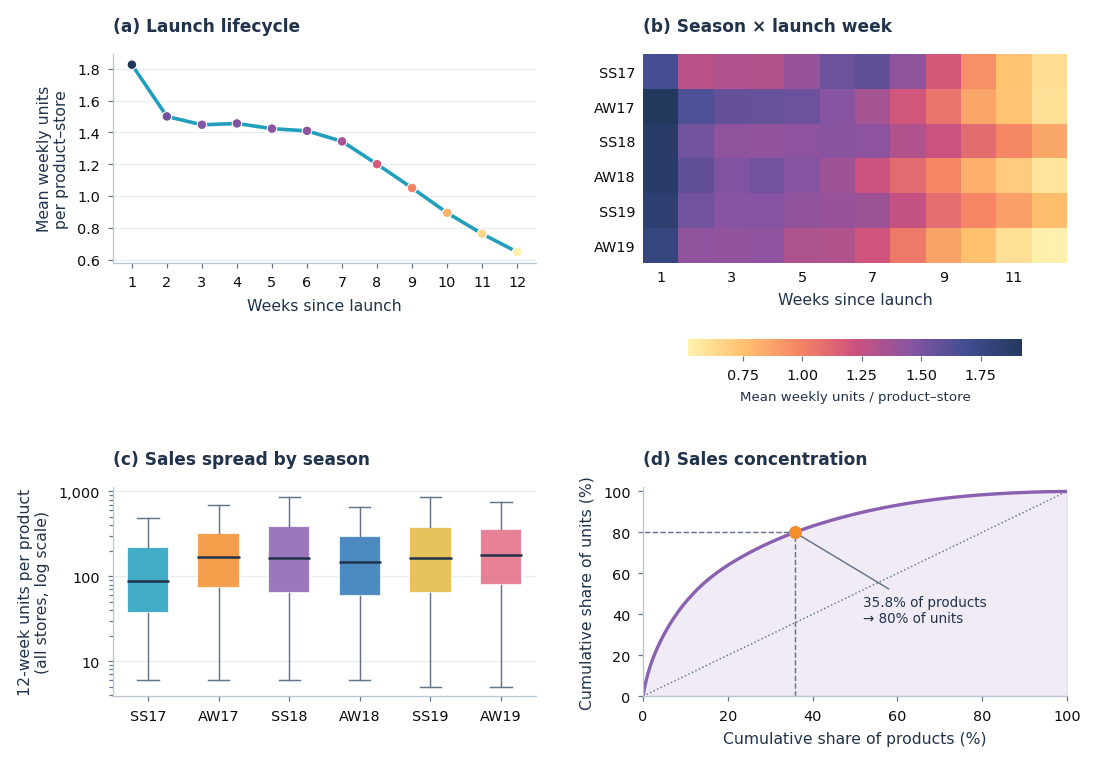

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(DOUBLE, 128 * MM), layout='constrained')
wk = np.arange(1, 13)
a = ax[0, 0]
m, e = sales[WEEKS].mean().values, np.array([ci95(sales[w]) for w in WEEKS])
a.fill_between(wk, m - e, m + e, color=PAL[0], alpha=.22, lw=0)
a.plot(wk, m, color=PAL[0], lw=1.7)
a.scatter(wk, m, c=[SEQ((v - m.min()) / (m.max()-m.min())) for v in m], s=21, edgecolor='white', linewidth=.5, zorder=4)
a.set_xlabel('Weeks since launch'); a.set_ylabel('Mean weekly units\nper product–store'); a.set_xticks(wk); hgrid(a)
# A heatmap reveals every season/week value without six overlapping curves.
a = ax[0, 1]
life = sales.groupby('season')[WEEKS].mean().reindex(SEASONS)
im = a.imshow(life.values, cmap=SEQ, aspect='auto')
a.set_xticks(range(0,12,2), wk[::2]); a.set_yticks(range(6), SEASONS)
a.set_xlabel('Weeks since launch'); a.tick_params(length=0)
for spine in a.spines.values(): spine.set_visible(False)
cb = fig.colorbar(im, ax=a, orientation='horizontal', pad=.12, fraction=.08)
cb.set_label('Mean weekly units / product–store', fontsize=6.4); cb.outline.set_visible(False)
# Compare distributions rather than another aggregate curve.
a = ax[1, 0]
by_product = products[['season']].join(prod_sales.rename('units'))
values = [by_product.loc[by_product.season == s, 'units'].values for s in SEASONS]
boxes = a.boxplot(values, patch_artist=True, widths=.60, showfliers=False,
    medianprops={'color': INK, 'linewidth': 1.2},
    whiskerprops={'color': INK2, 'linewidth': .7}, capprops={'color': INK2, 'linewidth': .7})
for patch, color in zip(boxes['boxes'], SEASON_COLORS):
    patch.set_facecolor(color); patch.set_alpha(.85); patch.set_edgecolor('white')
a.set_xticks(range(1,7), SEASONS); a.set_yscale('log')
a.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{v:,.0f}'))
a.set_ylabel('12-week units per product\n(all stores, log scale)'); hgrid(a)
a = ax[1, 1]
s = prod_sales.sort_values(ascending=False)
x = np.arange(1, len(s)+1) / len(s)*100; y = s.cumsum().values / s.sum()*100
p80 = x[np.searchsorted(y, 80)]
a.fill_between(x, 0, y, color=PAL[2], alpha=.12); a.plot(x,y,color=PAL[2])
a.plot([0,100],[0,100], color=GREY,lw=.7,ls=':')
a.plot([p80,p80,0],[0,80,80], color=INK2,lw=.7,ls='--')
a.scatter([p80],[80],s=28,color=PAL[1],zorder=5)
a.annotate(f'{p80:.1f}% of products\n→ 80% of units', (p80,80), xytext=(p80+16,36),
    fontsize=6.5, arrowprops={'arrowstyle':'-', 'color':INK2,'lw':.7})
a.set_xlim(0,100); a.set_ylim(0,102)
a.set_xlabel('Cumulative share of products (%)'); a.set_ylabel('Cumulative share of units (%)')
save(fig, 'Fig2_sales_dynamics'); plt.show()


## Figure 3 — Hiệu quả theo danh mục

Saved: Fig3_category_performance (PNG)


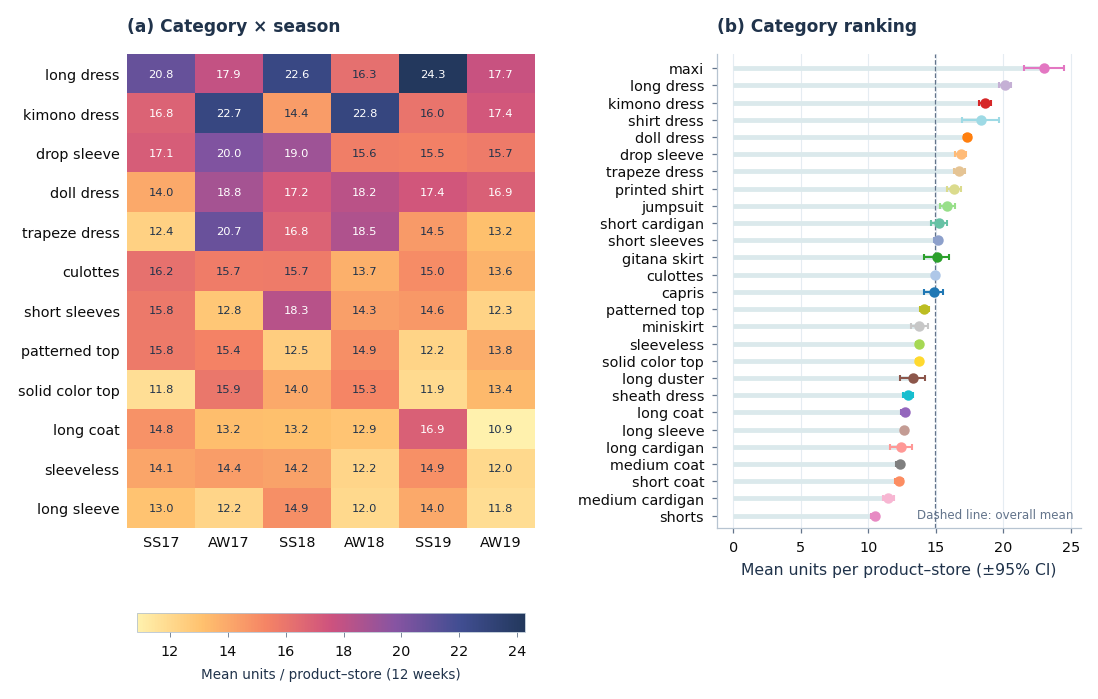

In [5]:
fig = plt.figure(figsize=(DOUBLE, 117 * MM), layout='constrained')
gs = fig.add_gridspec(1, 2, width_ratios=[1.12, 1])
a1, a2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

# (a) Heatmap danh mục × mùa (12 danh mục nhiều SP nhất)
top = products.category.value_counts().head(12).index
pv = sales[sales.category.isin(top)].pivot_table(index='category', columns='season', values='total', aggfunc='mean')[SEASONS]
pv = pv.loc[pv.mean(axis=1).sort_values(ascending=False).index]
im = a1.imshow(pv.values, cmap=SEQ, aspect='auto')
a1.set_xticks(range(len(SEASONS)), SEASONS); a1.set_yticks(range(len(pv)), pv.index)
a1.tick_params(length=0); [sp.set_visible(False) for sp in a1.spines.values()]
lo, hi = np.nanmin(pv.values), np.nanmax(pv.values)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        v = pv.values[i, j]
        if not np.isnan(v):
            a1.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=5.5,
                    color='white' if np.dot(im.cmap(im.norm(v))[:3], [.2126, .7152, .0722]) < .52 else INK)
cb = fig.colorbar(im, ax=a1, orientation='horizontal', shrink=.95, pad=.07, fraction=.06)
cb.set_label('Mean units / product–store (12 weeks)', fontsize=6.5); cb.outline.set_linewidth(0.4); cb.ax.tick_params(width=0.4)

# (b) Doanh số TB / cặp SP × cửa hàng theo danh mục ± 95% CI
g = sales.groupby('category').total.agg(['mean', ci95, 'size']).query('size >= 200').sort_values('mean')
a2.hlines(range(len(g)), 0, g['mean'], color='#DBE9EC', linewidth=2.3)
for i, (category, row) in enumerate(g.iterrows()):
    a2.errorbar(row['mean'], i, xerr=row['ci95'], fmt='o', color=CAT_COLORS[category], ms=4, elinewidth=1, capsize=1.5)
a2.axvline(sales.total.mean(), color=GREY, lw=0.6, ls='--')
a2.text(.98, .02, 'Dashed line: overall mean', transform=a2.transAxes, fontsize=5.7, color=INK2, ha='right')
a2.set_yticks(range(len(g)), g.index); a2.set_ylim(-0.7, len(g) - 0.2)
a2.set_xlabel('Mean units per product–store (±95% CI)'); hgrid(a2, 'x')

panel(a1, 'a', dx=-60); panel(a2, 'b', dx=-62)
save(fig, 'Fig3_category_performance'); plt.show()

## Figure 4 — Giá và giảm giá

Saved: Fig4_price_discount (PNG)


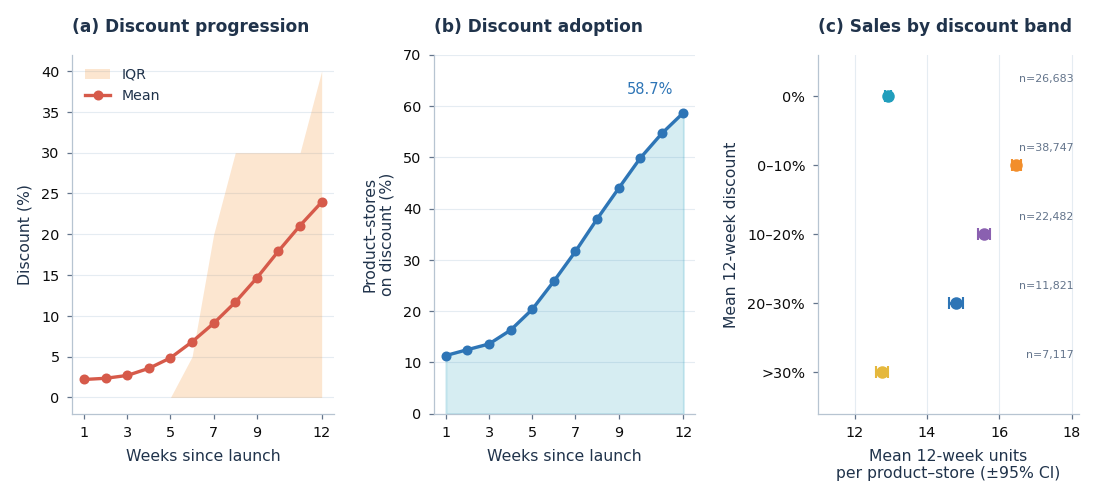

83

In [6]:
sp = sales.merge(price.rename(columns={w: f'd{w}' for w in WEEKS}), on=['external_code', 'retail'], how='left')
D = sp[[f'd{w}' for w in WEEKS]] * 100
sp['avg_disc'] = D.mean(axis=1)
sp['disc_bin'] = pd.cut(sp.avg_disc, [-.01,0,10,20,30,100], labels=['0','0–10','10–20','20–30','>30'])
fig, ax = plt.subplots(1,3,figsize=(DOUBLE,83*MM),layout='constrained')
a=ax[0]; q=D.quantile([.25,.75]).values
a.fill_between(wk,q[0],q[1],color=PAL[1],alpha=.22,lw=0,label='IQR')
a.plot(wk,D.mean().values,color=PAL[7],marker='o',label='Mean')
a.set_xticks([1,3,5,7,9,12]); a.set_xlabel('Weeks since launch'); a.set_ylabel('Discount (%)')
a.legend(loc='upper left'); hgrid(a)
a=ax[1]; adoption=(D>0).mean().values*100
a.fill_between(wk,0,adoption,color=PAL[0],alpha=.18)
a.plot(wk,adoption,color=PAL[3],marker='o')
a.annotate(f'{adoption[-1]:.1f}%', (12,adoption[-1]), xytext=(-5,9),textcoords='offset points',ha='right',fontsize=7,color=PAL[3])
a.set_xticks([1,3,5,7,9,12]); a.set_xlabel('Weeks since launch'); a.set_ylabel('Product–stores\non discount (%)')
a.set_ylim(0,70); hgrid(a)
a=ax[2]; g=sp.groupby('disc_bin',observed=True).total.agg(['mean',ci95,'size'])
for i, (band,row) in enumerate(g.iterrows()):
    a.errorbar(row['mean'],i,xerr=row['ci95'],fmt='o',color=PAL[i],ms=5,elinewidth=1.3,capsize=3)
    a.text(.98,i-.18,f"n={int(row['size']):,}",transform=a.get_yaxis_transform(),ha='right',va='bottom',fontsize=5.3,color=INK2)
a.set_yticks(range(len(g)), [f'{band}%' for band in g.index]); a.invert_yaxis()
a.set_ylabel('Mean 12-week discount'); a.set_xlabel('Mean 12-week units\nper product–store (±95% CI)')
a.margins(x=.4,y=.15); hgrid(a,'x')
save(fig, 'Fig4_price_discount'); plt.show()
del sp,D; plt.close('all'); gc.collect()


## Figure 5 — Hành vi khách hàng

In [7]:
customers = pd.read_csv(DATA / 'customer_data.csv', parse_dates=['data'],
                        dtype={'customer': 'int32', 'retail': 'int16', 'external_code': 'int16', 'qty': 'int8'})
orders = customers.groupby(['customer', 'retail', 'data'], sort=False).qty.sum().rename('items').reset_index()
del customers
per_cust = orders.groupby('customer').size()
print(f'{len(orders):,} đơn hàng, {len(per_cust):,} khách hàng')

1,757,698 đơn hàng, 665,285 khách hàng


Saved: Fig5_customer_behaviour (PNG)


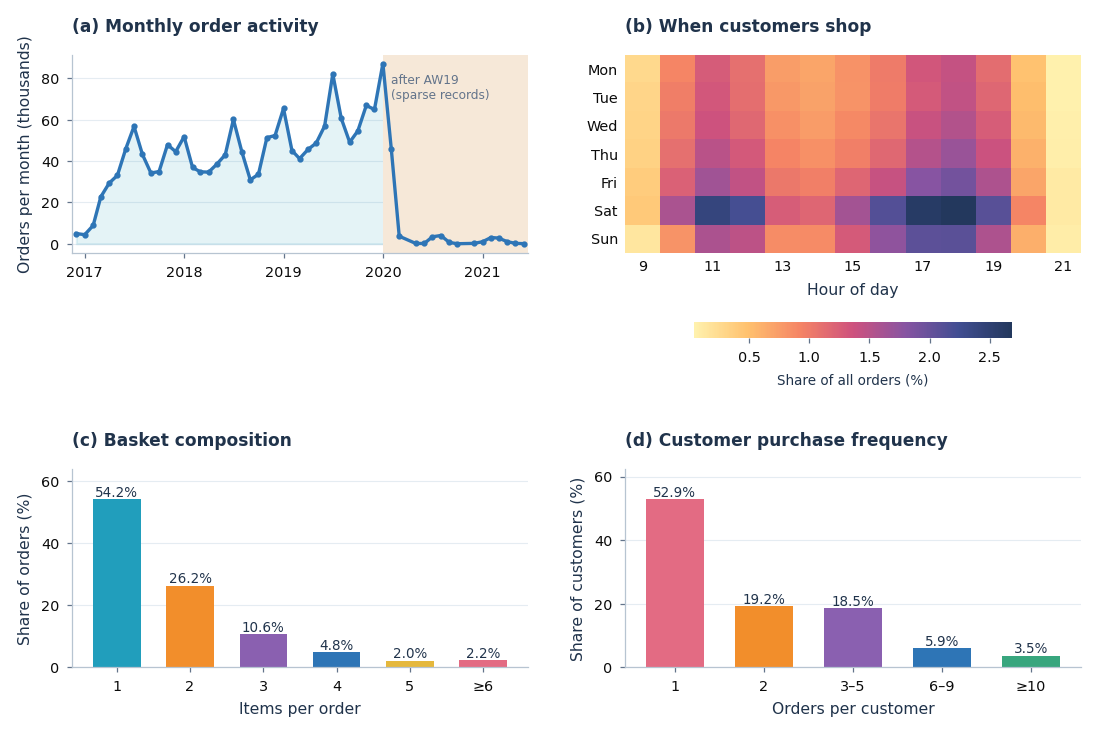

89

In [8]:
fig, ax = plt.subplots(2,2,figsize=(DOUBLE,123*MM),layout='constrained')
a_m,a_h,a_b,a_f=ax.flat
mo=orders.groupby(orders.data.dt.to_period('M')).size(); mo.index=mo.index.to_timestamp()
a_m.fill_between(mo.index,0,mo.values/1000,color=PAL[0],alpha=.12)
a_m.plot(mo.index,mo.values/1000,color=PAL[3],marker='o',ms=2)
a_m.axvspan(pd.Timestamp('2020-01-01'),mo.index.max()+pd.Timedelta(days=15),color='#F6E8D8',lw=0)
a_m.text(pd.Timestamp('2020-02-01'),a_m.get_ylim()[1]*.9,'after AW19\n(sparse records)',fontsize=5.8,color=INK2,va='top')
a_m.xaxis.set_major_locator(mdates.YearLocator()); a_m.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
a_m.set_ylabel('Orders per month (thousands)'); a_m.set_xlim(mo.index.min()-pd.Timedelta(days=15),mo.index.max()+pd.Timedelta(days=15)); hgrid(a_m)
hrs=range(9,22)
hm=pd.crosstab(orders.data.dt.dayofweek,orders.data.dt.hour,normalize='all')*100
hm=hm.reindex(columns=hrs,fill_value=0)
im=a_h.imshow(hm.values,cmap=SEQ,aspect='auto')
a_h.set_yticks(range(7),['Mon','Tue','Wed','Thu','Fri','Sat','Sun'])
a_h.set_xticks(range(0,len(hrs),2),list(hrs)[::2]); a_h.set_xlabel('Hour of day')
a_h.tick_params(length=0)
for spine in a_h.spines.values(): spine.set_visible(False)
cb=fig.colorbar(im,ax=a_h,orientation='horizontal',shrink=.95,pad=.12,fraction=.08)
cb.set_label('Share of all orders (%)',fontsize=6.5); cb.outline.set_visible(False)
bs=orders['items'].clip(upper=6).value_counts(normalize=True).sort_index()*100
a_b.bar(range(len(bs)),bs.values,color=categorical_colors(len(bs)),width=.65)
a_b.set_xticks(range(len(bs)),[str(i) for i in bs.index[:-1]]+['≥6'])
for i,v in enumerate(bs): a_b.text(i,v,f'{v:.1f}%',ha='center',va='bottom',fontsize=6.5,color=INK)
a_b.set_xlabel('Items per order'); a_b.set_ylabel('Share of orders (%)'); a_b.margins(y=.18); hgrid(a_b)
# A linear percentage scale exposes the balance between one-time and repeat customers.
bins=pd.cut(per_cust,[0,1,2,5,9,np.inf],labels=['1','2','3–5','6–9','≥10'])
fq=bins.value_counts(sort=False)/len(per_cust)*100
a_f.bar(range(len(fq)),fq.values,color=[PAL[5],PAL[1],PAL[2],PAL[3],PAL[6]],width=.65)
for i,v in enumerate(fq): a_f.text(i,v,f'{v:.1f}%',ha='center',va='bottom',fontsize=6.5,color=INK)
a_f.set_xticks(range(len(fq)),fq.index); a_f.set_xlabel('Orders per customer'); a_f.set_ylabel('Share of customers (%)')
a_f.margins(y=.18); hgrid(a_f)
save(fig,'Fig5_customer_behaviour'); plt.show()
del orders,per_cust,hm; plt.close('all'); gc.collect()


## Figure 6 — Yếu tố ngoại sinh: Google Trends & nhiệt độ địa phương

Nhiệt độ được ghép **theo từng cửa hàng** qua `shop_weather_pairs.pt` (cửa hàng → địa phương), lấy nhiệt độ trung bình
của đúng tuần bán hàng đó, sau đó gom nhóm theo khoảng 2 °C.

In [9]:
pairs = torch.load(DATA / 'shop_weather_pairs.pt', weights_only=True)
weather = pd.read_csv(DATA / 'vis2_weather_data.csv', usecols=['locality', 'date', 'avg temp °C'])
weather['date'] = pd.to_datetime(weather['date'], format='%d/%m/%Y')
weather['wk'] = weather.date - pd.to_timedelta(weather.date.dt.dayofweek, unit='D')   # đầu tuần (thứ Hai)
wtemp = weather.groupby(['locality', 'wk'])['avg temp °C'].mean().rename('temp').reset_index()

long = sales[['retail', 'season', 'release_date'] + WEEKS].melt(
    id_vars=['retail', 'season', 'release_date'], var_name='w', value_name='qty')
long['qty'] = long.qty.astype('float32'); long['w'] = long.w.astype('int8')
long['season'] = long.season.astype('category')
long['wk'] = long.release_date + pd.to_timedelta(long.w.astype(int) * 7, unit='D')
long['wk'] -= pd.to_timedelta(long.wk.dt.dayofweek, unit='D')
long['locality'] = long.retail.map(pairs)
long = long.dropna(subset=['locality']).drop(columns=['release_date', 'retail'])
long = long.astype({'locality': 'int64'}).merge(wtemp, on=['locality', 'wk'], how='inner')
long['stype'] = long.season.str[:2]
gc.collect()
long['tbin'] = (long.temp // 2) * 2 + 1
# Chỉ số doanh số đã hiệu chỉnh vòng đời: chia cho doanh số TB của cùng mùa ở cùng tuần-kể-từ-ra-mắt
long['idx'] = long.qty / long.groupby(['season', 'w']).qty.transform('mean')
print(f'{len(long):,} quan sát tuần × SP × cửa hàng có nhiệt độ')
for st in ['SS', 'AW']:
    d = long[long.stype == st]
    print(f'{st}: Spearman(nhiệt độ, doanh số thô) = {d.temp.corr(d.qty, method="spearman"):+.3f} | '
          f'Spearman(nhiệt độ, chỉ số hiệu chỉnh vòng đời) = {d.temp.corr(d.idx, method="spearman"):+.3f}')

1,195,168 quan sát tuần × SP × cửa hàng có nhiệt độ


SS: Spearman(nhiệt độ, doanh số thô) = -0.058 | Spearman(nhiệt độ, chỉ số hiệu chỉnh vòng đời) = +0.005


AW: Spearman(nhiệt độ, doanh số thô) = +0.109 | Spearman(nhiệt độ, chỉ số hiệu chỉnh vòng đời) = +0.060


Saved: Fig6_exogenous_signals (PNG)


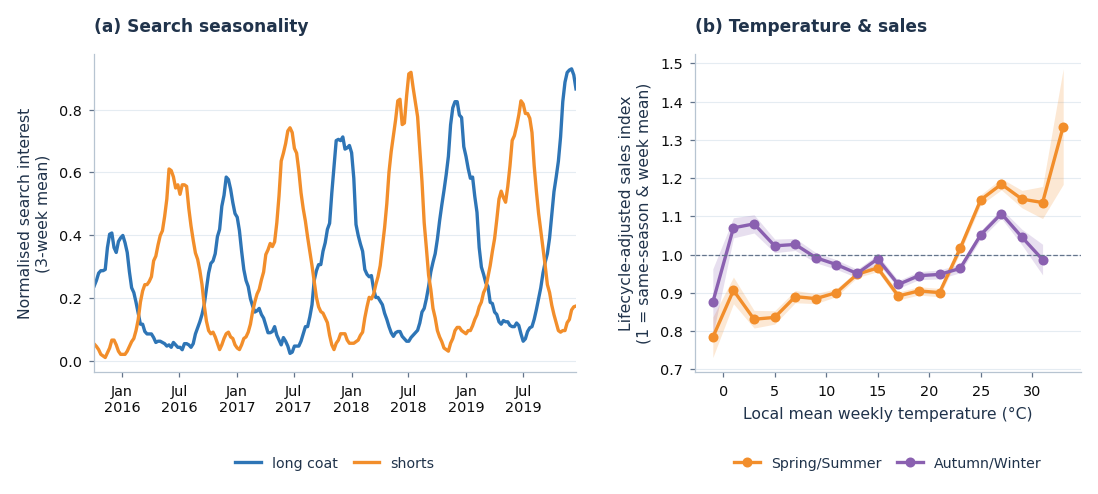

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(DOUBLE, 82 * MM), layout='constrained', gridspec_kw={'width_ratios': [1.25, 1]})

# (a) Google Trends (chuẩn hóa về [0, 1] cho từng chuỗi)
a = ax[0]
terms = ['long coat', 'shorts']
gt = gtrends.set_index('date')[terms]; gt = (gt - gt.min()) / (gt.max() - gt.min())
gt = gt.rolling(3, center=True, min_periods=1).mean()
for t, c in zip(terms, [PAL[3], PAL[1]]):
    a.plot(gt.index, gt[t], color=c, label=t)
a.set_ylabel('Normalised search interest\n(3-week mean)'); a.legend(ncol=2, loc='lower center', bbox_to_anchor=(0.5, -.35))
a.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); a.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
a.set_xlim(gt.index.min(), gt.index.max()); hgrid(a)

# (b) Doanh số tuần vs nhiệt độ địa phương
a = ax[1]
for st, lab, c in [('SS', 'Spring/Summer', PAL[1]), ('AW', 'Autumn/Winter', PAL[2])]:
    g = long[long.stype == st].groupby('tbin').idx.agg(['mean', ci95, 'size']).query('size >= 500')
    a.fill_between(g.index, g['mean'] - g['ci95'], g['mean'] + g['ci95'], color=c, alpha=0.2, lw=0)
    a.plot(g.index, g['mean'], color=c, marker='o', label=lab)
a.axhline(1, color=GREY, lw=0.6, ls='--')
a.set_xlabel('Local mean weekly temperature (°C)'); a.set_ylabel('Lifecycle-adjusted sales index\n(1 = same-season & week mean)')
a.legend(ncol=2, loc='lower center', bbox_to_anchor=(0.5, -.35)); hgrid(a)

for a, l in zip(ax, 'ab'): panel(a, l)
save(fig, 'Fig6_exogenous_signals'); plt.show()
del long, weather

## Figure S1 — Ảnh sản phẩm bán chạy / bán chậm (phụ lục)

Saved: FigS1_product_images (PNG)


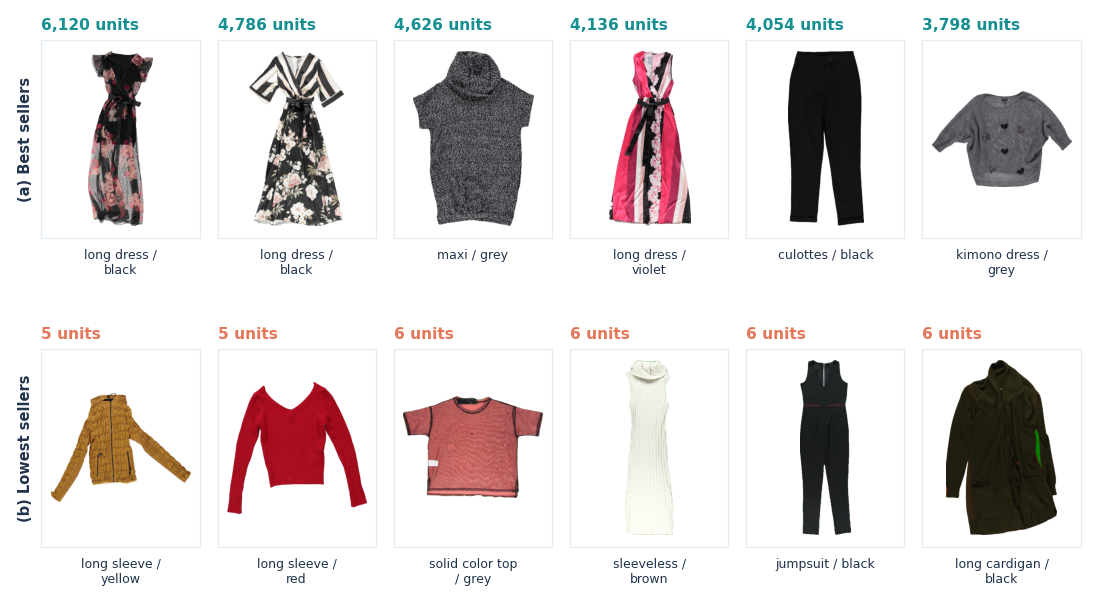

In [11]:
top6 = prod_sales.sort_values(ascending=False).head(6).index
bot6 = prod_sales.sort_values().head(6).index
fig, ax = plt.subplots(2, 6, figsize=(DOUBLE, 103 * MM), layout='constrained')
for r, items in enumerate([top6, bot6]):
    for a, c in zip(ax[r], items):
        im = Image.open(DATA / 'images' / products.loc[c, 'image_path']).convert('RGBA')
        bg = Image.new('RGBA', im.size, 'white'); bg.alpha_composite(im)
        ratio = im.width / im.height
        width = min(.88, ratio * 1.10); height = width / ratio
        a.imshow(bg.convert('RGB'), extent=(.5-width/2, .5+width/2, .625-height/2, .625+height/2))
        a.set_xlim(0, 1); a.set_ylim(0, 1.25); a.set_aspect('equal')
        a.set_xticks([]); a.set_yticks([])
        [s_.set_visible(False) for s_ in a.spines.values()]
        a.set_title(f'{int(prod_sales[c]):,} units', fontsize=7.4, color=TEAL if r == 0 else CORAL, pad=5)
        import textwrap
        a.set_xlabel(textwrap.fill(f"{products.loc[c, 'category']} / {products.loc[c, 'color']}", 16), fontsize=6, labelpad=5)
        for spine in a.spines.values():
            spine.set_visible(True); spine.set_edgecolor('#E5ECF2'); spine.set_linewidth(.6)
ax[0, 0].set_ylabel('(a) Best sellers', fontsize=7, fontweight='bold')
ax[1, 0].set_ylabel('(b) Lowest sellers', fontsize=7, fontweight='bold')
panel(ax[0, 0], 'a', dx=-30); panel(ax[1, 0], 'b', dx=-30)
save(fig, 'FigS1_product_images'); plt.show()

In [12]:
sorted(p.name for p in OUT.iterdir())

['Fig1_dataset_overview.png',
 'Fig2_sales_dynamics.png',
 'Fig3_category_performance.png',
 'Fig4_price_discount.png',
 'Fig5_customer_behaviour.png',
 'Fig6_exogenous_signals.png',
 'FigS1_product_images.png']